# Nhiệm Vụ 1: Bài Toán N Quân Hậu (N-Queen)

Sổ tay thực nghiệm đầy đủ 3 tiểu mục theo yêu cầu đồ án môn **503043 – Nhập môn Trí tuệ Nhân tạo**:
1. **Yêu cầu 1.1:** Mô hình hóa Logic mệnh đề, thuật toán phát hiện nhóm ràng buộc và chuyển đổi sang Dạng chuẩn hội (CNF).
2. **Yêu cầu 1.2:** Thực nghiệm bộ giải **Glucose3 (`PySAT`)** với $N \ge 4$ tăng dần ($N \in [4, 80]$), thống kê tổng số mệnh đề CNF, thời gian chạy và chỉ số bộ giải.
3. **Yêu cầu 1.3:** Cài đặt **Min-Conflicts** (Lecture 08), đề xuất heuristic chọn biến **Max-Conflict + Tabu thích nghi** và đối sánh công bằng trên cùng tập bàn cờ khởi tạo ($N \in [8, 200]$).

In [1]:
# Thiet lap moi truong, font tieng Viet cho Matplotlib va bang mau toi gian 3 tong
import random
import sys
from pathlib import Path
from statistics import mean, median

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.edgecolor'] = '#D1D5DB'
plt.rcParams['axes.linewidth'] = 0.9

COLOR_PRIMARY = '#0F766E'
COLOR_ALERT = '#C83E37'
COLOR_INK = '#111827'
COLOR_MUTED = '#6B7280'

current = Path.cwd().resolve()
for candidate in (current, *current.parents):
    if (candidate / 'task1' / 'board.py').exists():
        source_dir = candidate
        break
    if (candidate / 'source' / 'task1' / 'board.py').exists():
        source_dir = candidate / 'source'
        break
else:
    raise RuntimeError('Khong tim thay thu muc source/task1')

if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from task1 import (
    AdaptiveTabuMaxConflictSelector,
    Glucose3NQueenSolver,
    MinConflictsSolver,
    NQueenBoard,
    NQueenCNFEncoder,
    PureMaxConflictSelector,
    RandomConflictedSelector,
)

figure_dir = source_dir.parent / 'report' / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
print('Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 1 thành công.')

Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 1 thành công.


## Phần 1 (Yêu cầu 1.1): Mô Hình Logic Mệnh Đề & Quy Trình Chuyển Đổi CNF

Mỗi ô $(r, c)$ trên bàn cờ $N \times N$ được gán một biến mệnh đề $P_{r,c} \in \{\text{True}, \text{False}\}$, ánh xạ song ánh sang chỉ số nguyên dương DIMACS $\text{id}(r,c) = rN + c + 1 \in \{1, \dots, N^2\}$.
- **Ràng buộc tồn tại (At-Least-One – ALO):** Mỗi hàng $r$ (và bổ sung mỗi cột $c$) có ít nhất một quân hậu: $\bigvee_{c=0}^{N-1} P_{r,c}$.
- **Ràng buộc không tấn công (At-Most-One – AMO):** Mọi cặp ô phân biệt cùng hàng, cùng cột, cùng đường chéo chính ($r_1 - c_1 = r_2 - c_2$) hoặc đường chéo phụ ($r_1 + c_1 = r_2 + c_2$) thỏa phép kéo theo $P_{r_1,c_1} \Rightarrow \neg P_{r_2,c_2}$. Khử kéo theo thu được mệnh đề chuẩn CNF $(\neg P_{r_1,c_1} \vee \neg P_{r_2,c_2})$.
- **Công thức tổng số mệnh đề CNF (khi bật ALO cột):**
$$|C_{\text{CNF}}(N)| = 2N + N^2(N - 1) + \frac{N(N - 1)(2N - 1)}{3}$$

In [2]:
# Minh hoa chuyen doi rang buoc sang CNF cho N=4 va kiem chung cong thuc tong so menh de
enc_4 = NQueenCNFEncoder(n=4, include_col_alo=True)
rules_4 = enc_4.explain_cnf_conversion(sample_limit=2)
rules_df = pd.DataFrame([
    {
        'Loại ràng buộc': r.category,
        'Biểu thức Logic mệnh đề': r.logical_expr,
        'Dạng chuẩn hội (CNF)': r.cnf_expr,
        'Mệnh đề DIMACS': str(list(r.dimacs_clause)),
    }
    for r in rules_4
])
display(rules_df)

# Kiem chung cong thuc so menh de va truong hop vo nghiem N=2, N=3
verify_rows = []
sat_checker = Glucose3NQueenSolver(include_col_alo=True)
for n_val in [1, 2, 3, 4, 8, 12, 16, 20, 30, 50]:
    enc_with = NQueenCNFEncoder(n_val, include_col_alo=True)
    enc_no = NQueenCNFEncoder(n_val, include_col_alo=False)
    _, st_with = enc_with.encode()
    _, st_no = enc_no.encode()
    assert st_with.total_clauses == enc_with.theoretical_clause_count()
    assert st_no.total_clauses == enc_no.theoretical_clause_count()
    res_chk = sat_checker.solve(n_val, repeats=1)
    if n_val in (2, 3):
        assert not res_chk.satisfiable and res_chk.board is None
    else:
        assert res_chk.satisfiable and res_chk.board is not None and res_chk.board.is_valid_solution()
    verify_rows.append({
        'N': n_val,
        'Số biến (N^2)': st_with.num_variables,
        'ALO (Hàng+Cột)': st_with.row_alo_clauses + st_with.col_alo_clauses,
        'AMO Hàng+Cột': st_with.row_amo_clauses + st_with.col_amo_clauses,
        'AMO Đường chéo': st_with.diag_amo_clauses,
        'Tổng CNF (có ALO cột)': st_with.total_clauses,
        'Tổng CNF (chỉ ALO hàng)': st_no.total_clauses,
        'Trạng thái SAT': 'Có nghiệm hợp lệ' if res_chk.satisfiable else 'Vô nghiệm (UNSAT)',
    })
verify_df = pd.DataFrame(verify_rows)
verify_df

,Loại ràng buộc,Biểu thức Logic mệnh đề,Dạng chuẩn hội (CNF),Mệnh đề DIMACS
0,Ton tai theo hang (ALO),"P(0,0) v P(0,1) v P(0,2) v P(0,3)","P(0,0) v P(0,1) v P(0,2) v P(0,3)","[1, 2, 3, 4]"
1,Ton tai theo hang (ALO),"P(1,0) v P(1,1) v P(1,2) v P(1,3)","P(1,0) v P(1,1) v P(1,2) v P(1,3)","[5, 6, 7, 8]"
2,Ton tai theo cot (ALO),"P(0,0) v P(1,0) v P(2,0) v P(3,0)","P(0,0) v P(1,0) v P(2,0) v P(3,0)","[1, 5, 9, 13]"
3,Ton tai theo cot (ALO),"P(0,1) v P(1,1) v P(2,1) v P(3,1)","P(0,1) v P(1,1) v P(2,1) v P(3,1)","[2, 6, 10, 14]"
4,Khong tan cong cung hang (AMO),"P(0,0) => ~P(0,1)","~P(0,0) v ~P(0,1)","[-1, -2]"
5,Khong tan cong cung hang (AMO),"P(0,0) => ~P(0,2)","~P(0,0) v ~P(0,2)","[-1, -3]"
6,Khong tan cong cung cot (AMO),"P(0,0) => ~P(1,0)","~P(0,0) v ~P(1,0)","[-1, -5]"
7,Khong tan cong cung cot (AMO),"P(0,0) => ~P(2,0)","~P(0,0) v ~P(2,0)","[-1, -9]"
8,Khong tan cong cheo chinh (AMO),"P(0,0) => ~P(1,1)","~P(0,0) v ~P(1,1)","[-1, -6]"
9,Khong tan cong cheo chinh (AMO),"P(0,0) => ~P(2,2)","~P(0,0) v ~P(2,2)","[-1, -11]"


,N,Số biến (N^2),ALO (Hàng+Cột),AMO Hàng+Cột,AMO Đường chéo,Tổng CNF (có ALO cột),Tổng CNF (chỉ ALO hàng),Trạng thái SAT
0,1,1,2,0,0,2,1,Có nghiệm hợp lệ
1,2,4,4,4,2,10,8,Vô nghiệm (UNSAT)
2,3,9,6,18,10,34,31,Vô nghiệm (UNSAT)
3,4,16,8,48,28,84,80,Có nghiệm hợp lệ
4,8,64,16,448,280,744,736,Có nghiệm hợp lệ
5,12,144,24,1584,1012,2620,2608,Có nghiệm hợp lệ
6,16,256,32,3840,2480,6352,6336,Có nghiệm hợp lệ
7,20,400,40,7600,4940,12580,12560,Có nghiệm hợp lệ
8,30,900,60,26100,17110,43270,43240,Có nghiệm hợp lệ
9,50,2500,100,122500,80850,203450,203400,Có nghiệm hợp lệ


## Phần 2 (Yêu cầu 1.2): Thực Nghiệm Bộ Giải SAT `Glucose3` (`PySAT`)

Khảo sát dải kích thước tăng dần $N \in [4, 80]$ (mỗi mức $N$ chạy lặp 3 lần sau bước khởi động để lấy **trung vị** thời gian ổn định, tách rõ thời gian mã hóa CNF và thời gian giải của `Glucose3`, đồng thời thu thập thống kê nội bộ `decisions`, `conflicts`, `propagations`, `restarts`).

In [3]:
# Khoi dong nhe va chay thuc nghiem Glucose3 tren dai N = 4..80
sat_solver = Glucose3NQueenSolver(include_col_alo=True)
sat_solver.solve(4, repeats=1)

sat_sizes = [4, 6, 8, 10, 12, 16, 20, 25, 30, 35, 40, 50, 60, 70, 80]
sat_rows = []
for n_val in sat_sizes:
    res = sat_solver.solve(n_val, repeats=3)
    assert res.satisfiable and res.board is not None and res.board.is_valid_solution()
    assert res.num_clauses == NQueenCNFEncoder(n_val).theoretical_clause_count()
    sat_rows.append({
        'Kích thước N': n_val,
        'Số biến (N^2)': res.num_variables,
        'Tổng mệnh đề CNF': res.num_clauses,
        'Mã hóa CNF (ms)': round(res.encoding_time_sec * 1000, 2),
        'Giải Glucose3 (ms)': round(res.solve_time_sec * 1000, 2),
        'Tổng thời gian (ms)': round(res.total_time_sec * 1000, 2),
        'Quyết định': res.decisions,
        'Xung đột CDCL': res.conflicts,
        'Lan truyền đơn vị': res.propagations,
        'Nghiệm hợp lệ': 'Đúng',
    })
sat_results = pd.DataFrame(sat_rows)
sat_results

,Kích thước N,Số biến (N^2),Tổng mệnh đề CNF,Mã hóa CNF (ms),Giải Glucose3 (ms),Tổng thời gian (ms),Quyết định,Xung đột CDCL,Lan truyền đơn vị,Nghiệm hợp lệ
0,4,16,84,0.27,0.66,0.94,12,2,28,Đúng
1,6,36,302,0.39,0.63,1.02,18,7,96,Đúng
2,8,64,744,0.55,0.91,1.46,39,21,295,Đúng
3,10,100,1490,0.59,1.19,1.78,39,14,266,Đúng
4,12,144,2620,1.93,2.49,4.42,75,34,557,Đúng
5,16,256,6352,5.87,27.44,33.31,1195,952,15473,Đúng
6,20,400,12580,11.55,24.35,35.90,542,167,4101,Đúng
7,25,625,24850,12.81,31.66,44.46,475,212,5629,Đúng
8,30,900,43270,24.34,47.61,71.95,632,137,5390,Đúng
9,35,1225,69090,135.00,148.17,283.17,3268,1336,40766,Đúng


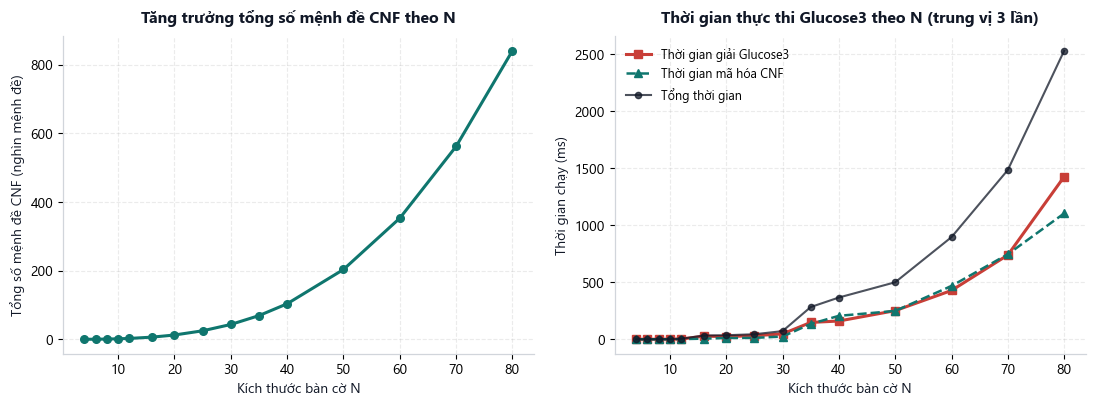

In [4]:
# Ve bieu do tang truong menh de CNF va thoi gian chay Glucose3 theo N
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3), facecolor='white')

axes[0].plot(
    sat_results['Kích thước N'],
    sat_results['Tổng mệnh đề CNF'] / 1000.0,
    marker='o', markersize=5.5, linewidth=2.2, color=COLOR_PRIMARY,
)
axes[0].set_title('Tăng trưởng tổng số mệnh đề CNF theo N', fontsize=11.5, fontweight='bold', color=COLOR_INK, pad=10)
axes[0].set_xlabel('Kích thước bàn cờ N', fontsize=10, color=COLOR_INK)
axes[0].set_ylabel('Tổng số mệnh đề CNF (nghìn mệnh đề)', fontsize=10, color=COLOR_INK)
axes[0].grid(alpha=0.25, linestyle='--')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

axes[1].plot(
    sat_results['Kích thước N'],
    sat_results['Giải Glucose3 (ms)'],
    marker='s', markersize=5.5, linewidth=2.2, color=COLOR_ALERT, label='Thời gian giải Glucose3',
)
axes[1].plot(
    sat_results['Kích thước N'],
    sat_results['Mã hóa CNF (ms)'],
    marker='^', markersize=5.5, linewidth=1.8, linestyle='--', color=COLOR_PRIMARY, label='Thời gian mã hóa CNF',
)
axes[1].plot(
    sat_results['Kích thước N'],
    sat_results['Tổng thời gian (ms)'],
    marker='o', markersize=4.5, linewidth=1.5, alpha=0.75, color=COLOR_INK, label='Tổng thời gian',
)
axes[1].set_title('Thời gian thực thi Glucose3 theo N (trung vị 3 lần)', fontsize=11.5, fontweight='bold', color=COLOR_INK, pad=10)
axes[1].set_xlabel('Kích thước bàn cờ N', fontsize=10, color=COLOR_INK)
axes[1].set_ylabel('Thời gian chạy (ms)', fontsize=10, color=COLOR_INK)
axes[1].grid(alpha=0.25, linestyle='--')
axes[1].legend(frameon=False, fontsize=9)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.tight_layout(pad=1.6)
fig.savefig(figure_dir / 'task1_glucose3_scaling.png', dpi=180, bbox_inches='tight')
plt.show()

## Phần 3 (Yêu cầu 1.3): Tìm Kiếm Cục Bộ `Min-Conflicts` & Heuristic Đề Xuất

Đánh giá công bằng 3 chiến lược chọn biến trên **50 bàn cờ khởi tạo ngẫu nhiên dùng chung** cho từng kích thước $N \in \{8, 16, 32, 64, 100, 150, 200\}$ (cùng giới hạn `max_steps = 2500`, cùng luật chọn hàng cực tiểu xung đột chuẩn Lecture 08):
1. **Min-Conflicts tiêu chuẩn (Ngẫu nhiên):** Chọn ngẫu nhiên đều một cột đang xung đột.
2. **Max-Conflict thuần (Đối chứng):** Luôn chọn cột nhiều xung đột nhất (không có Tabu) — minh họa hiện tượng dễ kẹt chu trình trên bàn cờ nhỏ và vừa.
3. **Max-Conflict + Tabu thích nghi (Đề xuất):** Ưu tiên cột xung đột cao nhất chưa bị cấm (phá hòa theo tuổi lâu chưa sửa), kết hợp thời hạn cấm thích nghi theo quy mô tập xung đột $k = |C|$, điều kiện ân xá nhẹ khi gần đích và cơ chế nhiễu động phá cực trị cục bộ chặt (`1` cặp xung đột).

In [5]:
# Doi sanh cong bang 3 chien luoc chon bien tren 50 ban co khoi tao chung cho moi N
mc_sizes = [8, 16, 32, 64, 100, 150, 200]
trials = 50
max_steps = 2500
local_rows = []

for n_val in mc_sizes:
    boards = [
        NQueenBoard.from_random(n_val, random.Random(2026 + n_val * 131 + i))
        for i in range(trials)
    ]
    baseline_avg_steps = None
    for selector in (
        RandomConflictedSelector(),
        PureMaxConflictSelector(),
        AdaptiveTabuMaxConflictSelector(),
    ):
        solver = MinConflictsSolver(strategy=selector, max_steps=max_steps)
        runs = [
            solver.solve(n_val, initial_board=board, seed=9000 + i)
            for i, board in enumerate(boards)
        ]
        ok_cnt = sum(r.solved and r.board.is_valid_solution() for r in runs)
        avg_steps = mean(r.steps for r in runs)
        med_steps = median(r.steps for r in runs)
        avg_ms = 1000.0 * mean(r.elapsed_sec for r in runs)
        if baseline_avg_steps is None:
            baseline_avg_steps = avg_steps
            gain_pct = 0.0
        else:
            gain_pct = 100.0 * (baseline_avg_steps - avg_steps) / max(1e-9, baseline_avg_steps)

        local_rows.append({
            'Kích thước N': n_val,
            'Phương pháp chọn biến': selector.name,
            'Tỷ lệ thành công (%)': round(100.0 * ok_cnt / trials, 2),
            'Số bước TB': round(avg_steps, 2),
            'Trung vị bước': round(med_steps, 1),
            'Thời gian TB (ms)': round(avg_ms, 2),
            'Giảm bước so với chuẩn (%)': round(gain_pct, 1),
        })

local_results = pd.DataFrame(local_rows)
local_results

,Kích thước N,Phương pháp chọn biến,Tỷ lệ thành công (%),Số bước TB,Trung vị bước,Thời gian TB (ms),Giảm bước so với chuẩn (%)
0,8,Min-Conflicts tiêu chuẩn (Ngẫu nhiên),98.0,94.42,32.0,1.74,0.0
1,8,Max-Conflict thuần (Đối chứng),96.0,146.40,32.0,4.38,-55.1
2,8,Max-Conflict + Tabu thích nghi (Đề xuất),100.0,23.98,21.5,1.41,74.6
3,16,Min-Conflicts tiêu chuẩn (Ngẫu nhiên),98.0,116.92,48.0,10.37,0.0
4,16,Max-Conflict thuần (Đối chứng),92.0,253.66,49.0,32.42,-117.0
5,16,Max-Conflict + Tabu thích nghi (Đề xuất),100.0,48.26,35.5,2.26,58.7
6,32,Min-Conflicts tiêu chuẩn (Ngẫu nhiên),100.0,81.60,69.5,4.31,0.0
7,32,Max-Conflict thuần (Đối chứng),100.0,68.60,64.0,3.33,15.9
8,32,Max-Conflict + Tabu thích nghi (Đề xuất),100.0,70.10,47.5,3.62,14.1
9,64,Min-Conflicts tiêu chuẩn (Ngẫu nhiên),100.0,101.94,98.5,6.93,0.0


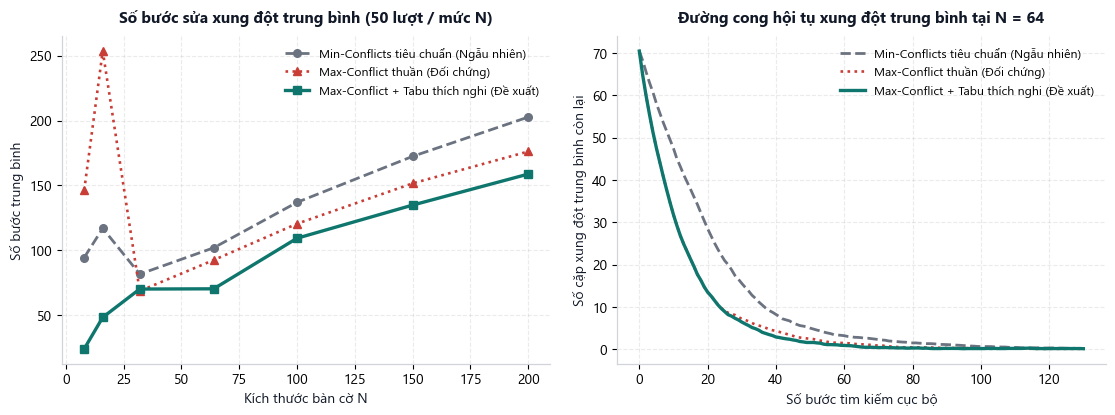

In [6]:
# Ve bieu do doi sanh so buoc TB va duong cong hoi tu xung dot tai N=64
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.4), facecolor='white')

style_map = {
    'Min-Conflicts tiêu chuẩn (Ngẫu nhiên)': (COLOR_MUTED, '--', 'o', 2.0),
    'Max-Conflict thuần (Đối chứng)': (COLOR_ALERT, ':', '^', 1.9),
    'Max-Conflict + Tabu thích nghi (Đề xuất)': (COLOR_PRIMARY, '-', 's', 2.4),
}

for method, group in local_results.groupby('Phương pháp chọn biến', sort=False):
    color, ls, marker, lw = style_map[method]
    axes[0].plot(
        group['Kích thước N'],
        group['Số bước TB'],
        color=color, linestyle=ls, marker=marker, markersize=5.5, linewidth=lw, label=method,
    )

axes[0].set_title('Số bước sửa xung đột trung bình (50 lượt / mức N)', fontsize=11.2, fontweight='bold', color=COLOR_INK, pad=10)
axes[0].set_xlabel('Kích thước bàn cờ N', fontsize=10, color=COLOR_INK)
axes[0].set_ylabel('Số bước trung bình', fontsize=10, color=COLOR_INK)
axes[0].grid(alpha=0.25, linestyle='--')
axes[0].legend(frameon=False, fontsize=8.8)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Ve duong cong hoi tu trung binh cua tong xung dot theo tung buoc tai N=64 (30 ban co chung)
conv_n = 64
conv_trials = 30
conv_boards = [NQueenBoard.from_random(conv_n, random.Random(7000 + i)) for i in range(conv_trials)]
horizon = 130
for selector in (RandomConflictedSelector(), PureMaxConflictSelector(), AdaptiveTabuMaxConflictSelector()):
    curves = []
    for i, b in enumerate(conv_boards):
        r = MinConflictsSolver(strategy=selector, max_steps=1000, record_history=True).solve(
            conv_n, initial_board=b, seed=8000 + i
        )
        hist = r.conflict_history[:horizon + 1]
        if len(hist) < horizon + 1:
            hist = hist + [0] * (horizon + 1 - len(hist))
        curves.append(hist)
    avg_curve = [mean(c[t] for c in curves) for t in range(horizon + 1)]
    color, ls, _, lw = style_map[selector.name]
    axes[1].plot(range(horizon + 1), avg_curve, color=color, linestyle=ls, linewidth=lw, label=selector.name)

axes[1].set_title('Đường cong hội tụ xung đột trung bình tại N = 64', fontsize=11.2, fontweight='bold', color=COLOR_INK, pad=10)
axes[1].set_xlabel('Số bước tìm kiếm cục bộ', fontsize=10, color=COLOR_INK)
axes[1].set_ylabel('Số cặp xung đột trung bình còn lại', fontsize=10, color=COLOR_INK)
axes[1].grid(alpha=0.25, linestyle='--')
axes[1].legend(frameon=False, fontsize=8.8)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.tight_layout(pad=1.6)
fig.savefig(figure_dir / 'task1_min_conflicts_comparison.png', dpi=180, bbox_inches='tight')
plt.show()